<a href="https://colab.research.google.com/github/UH-HACKATHON-TEAMN/Hackathon-Town-C/blob/main/HackathonS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:

# Upload the three CSV files
uploaded = files.upload()

# Load datasets
train_df = pd.read_csv("dataset_C_training.csv")
test_df = pd.read_csv("dataset_C_testing.csv")
example_submission = pd.read_csv(
    "dataset_C_example_submission.csv"
)

# Display dataset dimensions
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)
print("Submission shape:", example_submission.shape)


Saving dataset_C_example_submission.csv to dataset_C_example_submission (1).csv
Saving dataset_C_testing.csv to dataset_C_testing (1).csv
Saving dataset_C_training.csv to dataset_C_training (1).csv
Training shape: (4756, 31)
Testing shape: (4749, 30)
Submission shape: (4749, 2)


In [ ]:

# Display first five rows
print("First five training observations:")
display(train_df.head())

# Examine column names and data types
print("\nDataset information:")
train_df.info()

# Summary statistics
print("\nSummary statistics:")
display(train_df.describe(include="all").T)

# Check duplicates
print("\nDuplicate rows:")
print(train_df.duplicated().sum())

# Verify respondent IDs
print("\nAre respondent IDs unique?")
print(train_df["respondent_id"].is_unique)

# Target distribution
print("\nTarget distribution:")
print(train_df["covid_vaccine"].value_counts())

# Target percentages
print("\nTarget percentages:")
print(
    train_df["covid_vaccine"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


First five training observations:


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance          

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0



Duplicate rows:
0

Are respondent IDs unique?
True

Target distribution:
covid_vaccine
0    3202
1    1554
Name: count, dtype: int64

Target percentages:
covid_vaccine
0    67.33
1    32.67
Name: proportion, dtype: float64


,Missing Count,Missing Percentage
employment_sector,2330,48.990749
health_insurance,1908,40.117746
income_poverty,748,15.727502
rent_or_own,329,6.917578
employment_status,238,5.004205
marital_status,231,4.857023
education,228,4.793944
child_under_6_months,135,2.838520
health_worker,132,2.775442
opinion_covid_sick_from_vacc,90,1.892347


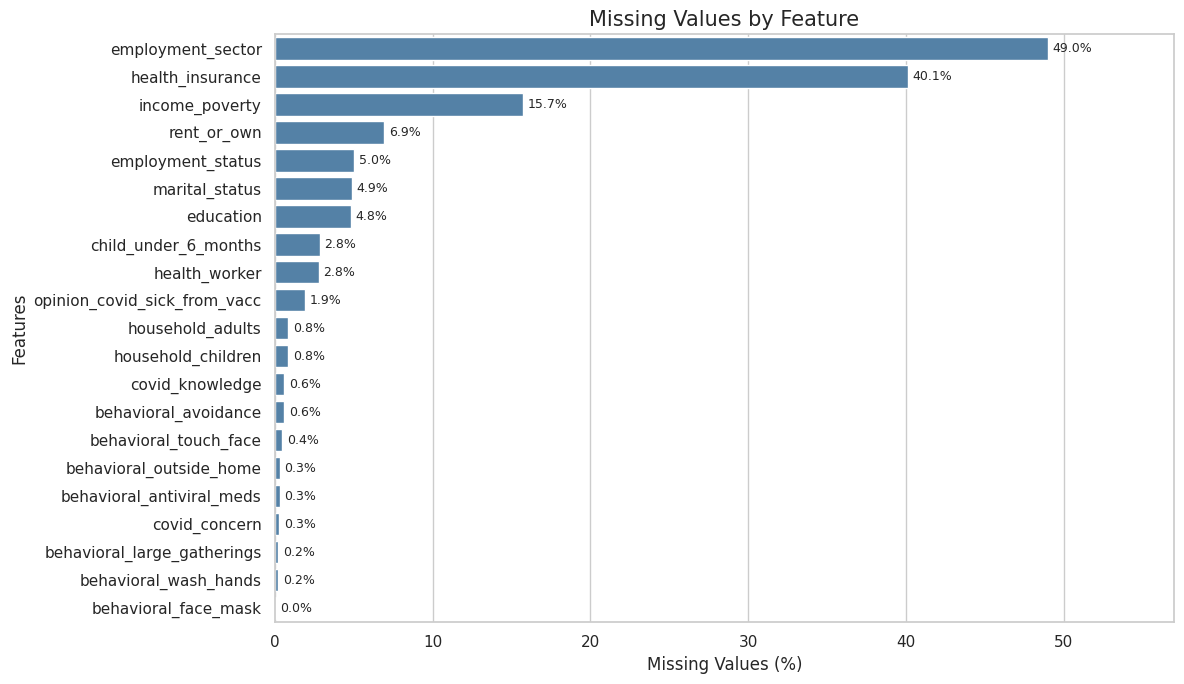

Total missing values: 6583


In [ ]:

# Calculate missing values
missing_count = train_df.isnull().sum()

missing_pct = (
    train_df.isnull().mean() * 100
).sort_values(ascending=False)

# Create missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_pct
}).sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary[missing_summary["Missing Count"] > 0])

# Visualise missing values
missing_features = missing_pct[missing_pct > 0]

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    x=missing_features.values,
    y=missing_features.index,
    color="steelblue"
)

for i, value in enumerate(missing_features.values):
    ax.text(value + 0.3, i, f"{value:.1f}%",
            va="center", fontsize=9)

plt.title("Missing Values by Feature", fontsize=15)
plt.xlabel("Missing Values (%)")
plt.ylabel("Features")
plt.xlim(0, max(missing_features.values) + 8)

plt.tight_layout()
plt.show()

print("Total missing values:", train_df.isnull().sum().sum())


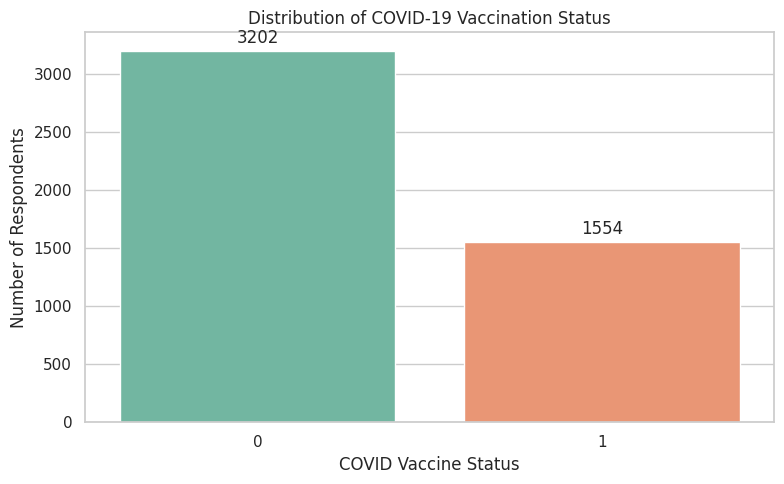

Class counts:
covid_vaccine
0    3202
1    1554
Name: count, dtype: int64

Class percentages:
covid_vaccine
0    67.33
1    32.67
Name: proportion, dtype: float64


In [ ]:

# Target distribution
target_counts = (
    train_df["covid_vaccine"]
    .value_counts()
    .sort_index()
)

target_pct = (
    train_df["covid_vaccine"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train_df,
    x="covid_vaccine",
    hue="covid_vaccine",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Distribution of COVID-19 Vaccination Status")
plt.xlabel("COVID Vaccine Status")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()

print("Class counts:")
print(target_counts)

print("\nClass percentages:")
print(target_pct.round(2))


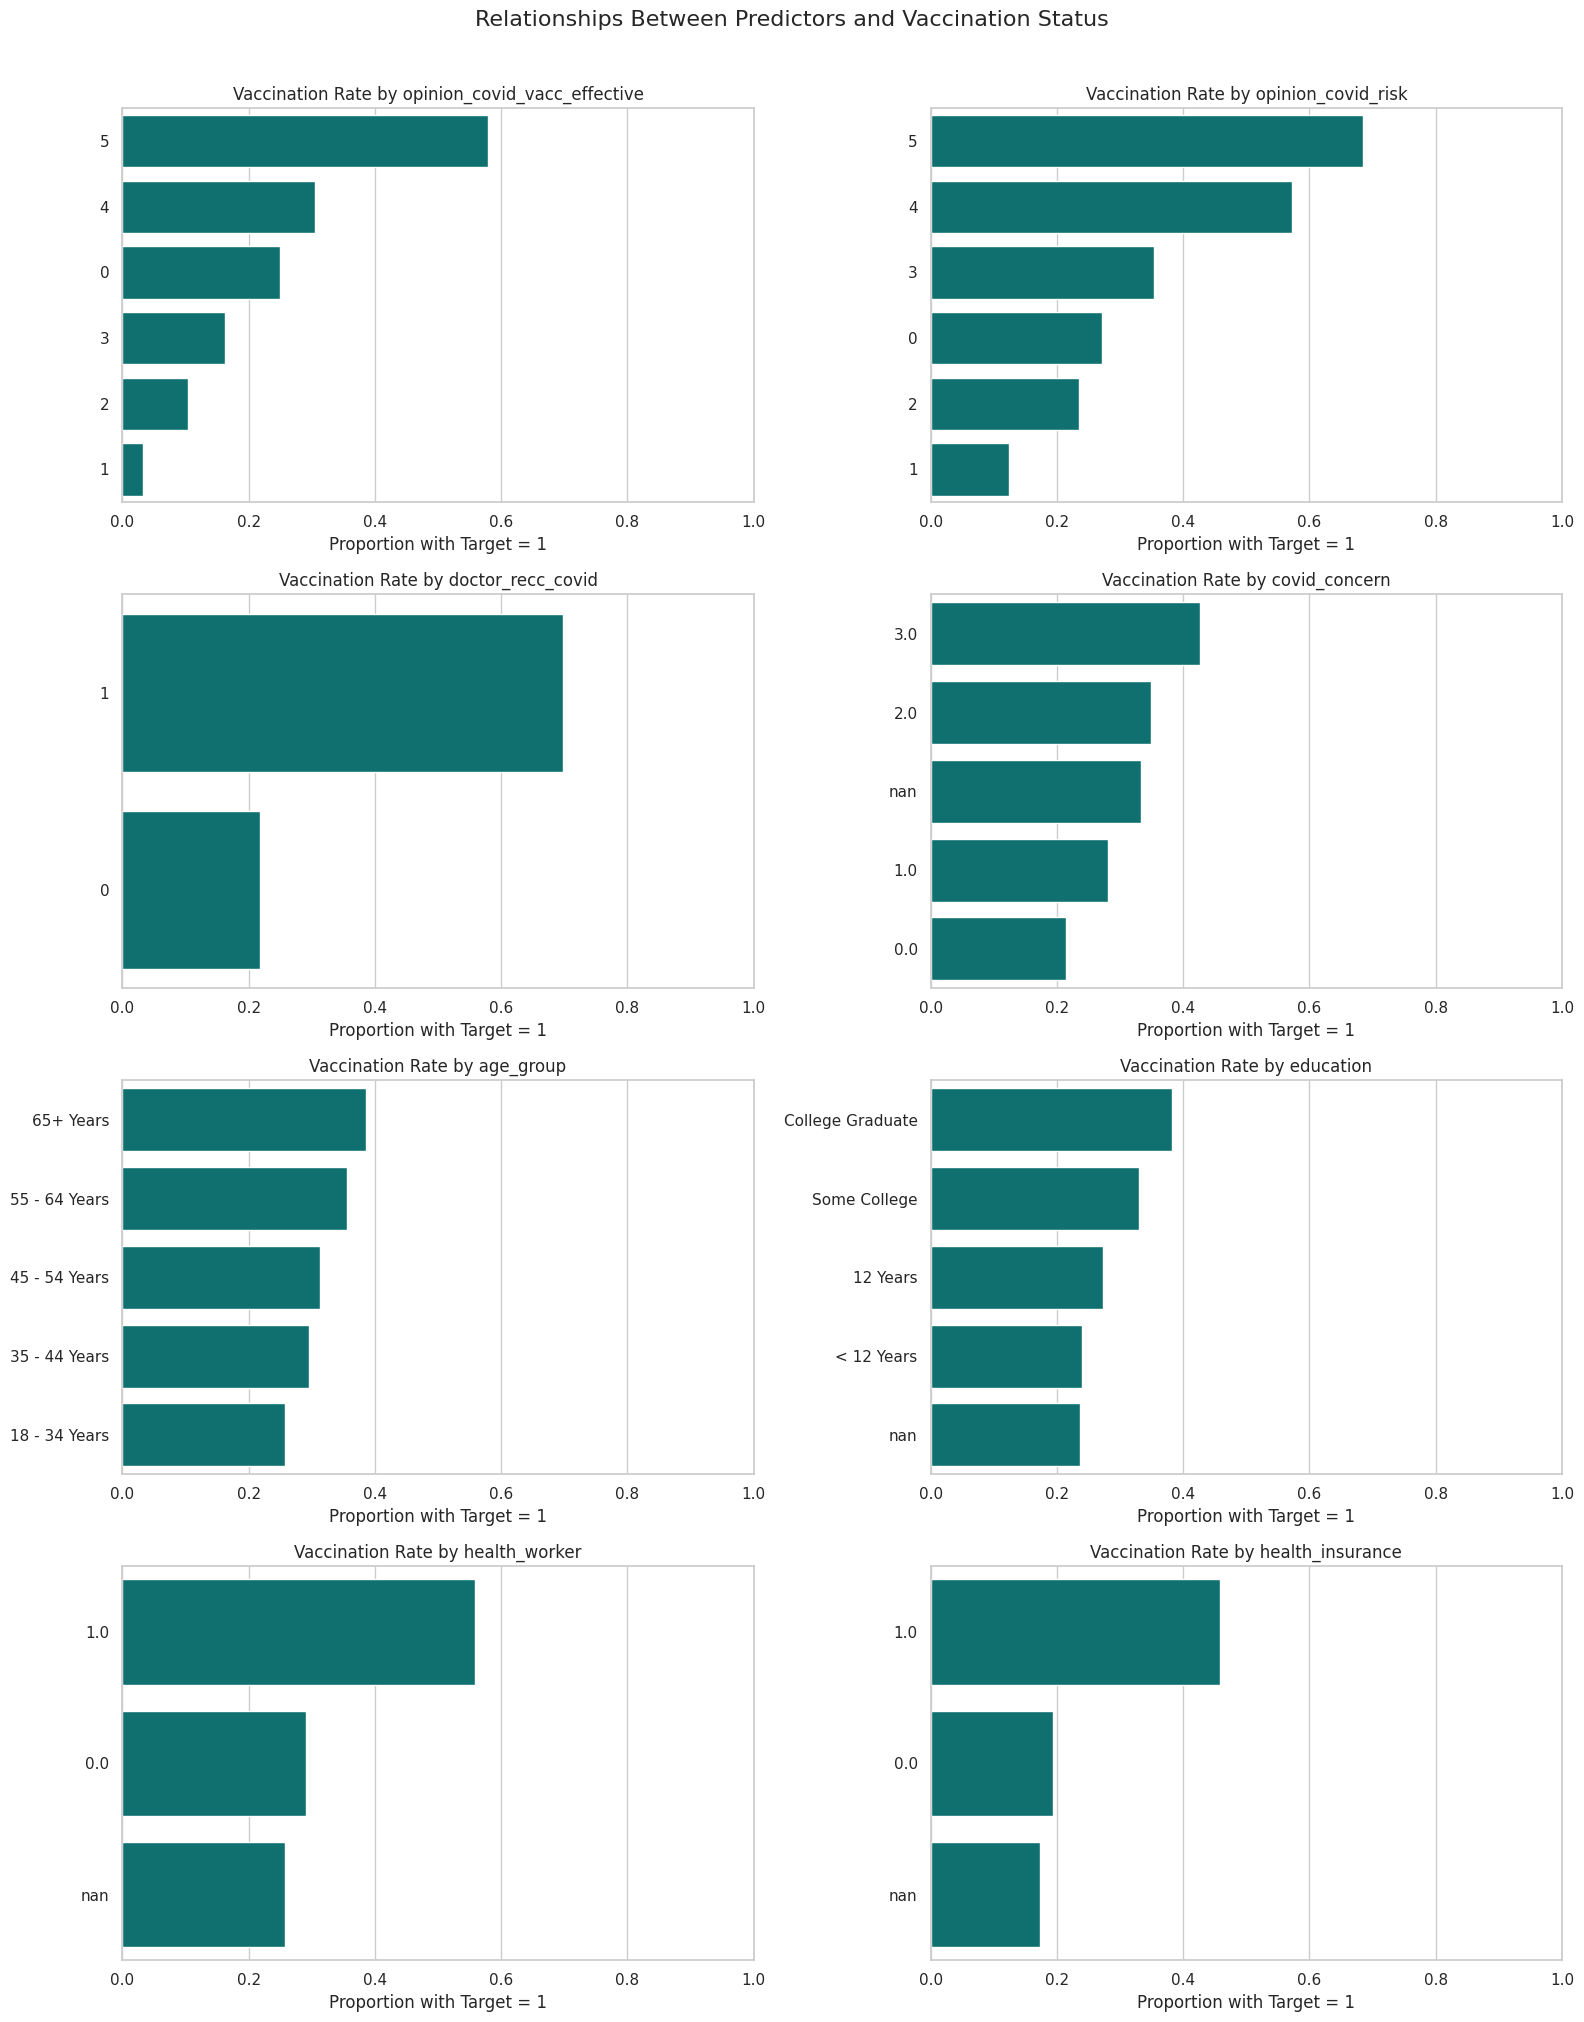

In [ ]:

features_to_explore = [
    "opinion_covid_vacc_effective",
    "opinion_covid_risk",
    "doctor_recc_covid",
    "covid_concern",
    "age_group",
    "education",
    "health_worker",
    "health_insurance"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

for i, feature in enumerate(features_to_explore):

    # Calculate target=1 rate by category
    rates = (
        train_df.groupby(feature, dropna=False)
        ["covid_vaccine"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
    )

    labels = rates.index.astype(str)

    sns.barplot(
        x=rates["mean"].values,
        y=labels,
        ax=axes[i],
        color="teal"
    )

    axes[i].set_title(
        f"Vaccination Rate by {feature}",
        fontsize=12
    )

    axes[i].set_xlabel("Proportion with Target = 1")
    axes[i].set_ylabel("")
    axes[i].set_xlim(0, 1)

plt.suptitle(
    "Relationships Between Predictors and Vaccination Status",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()


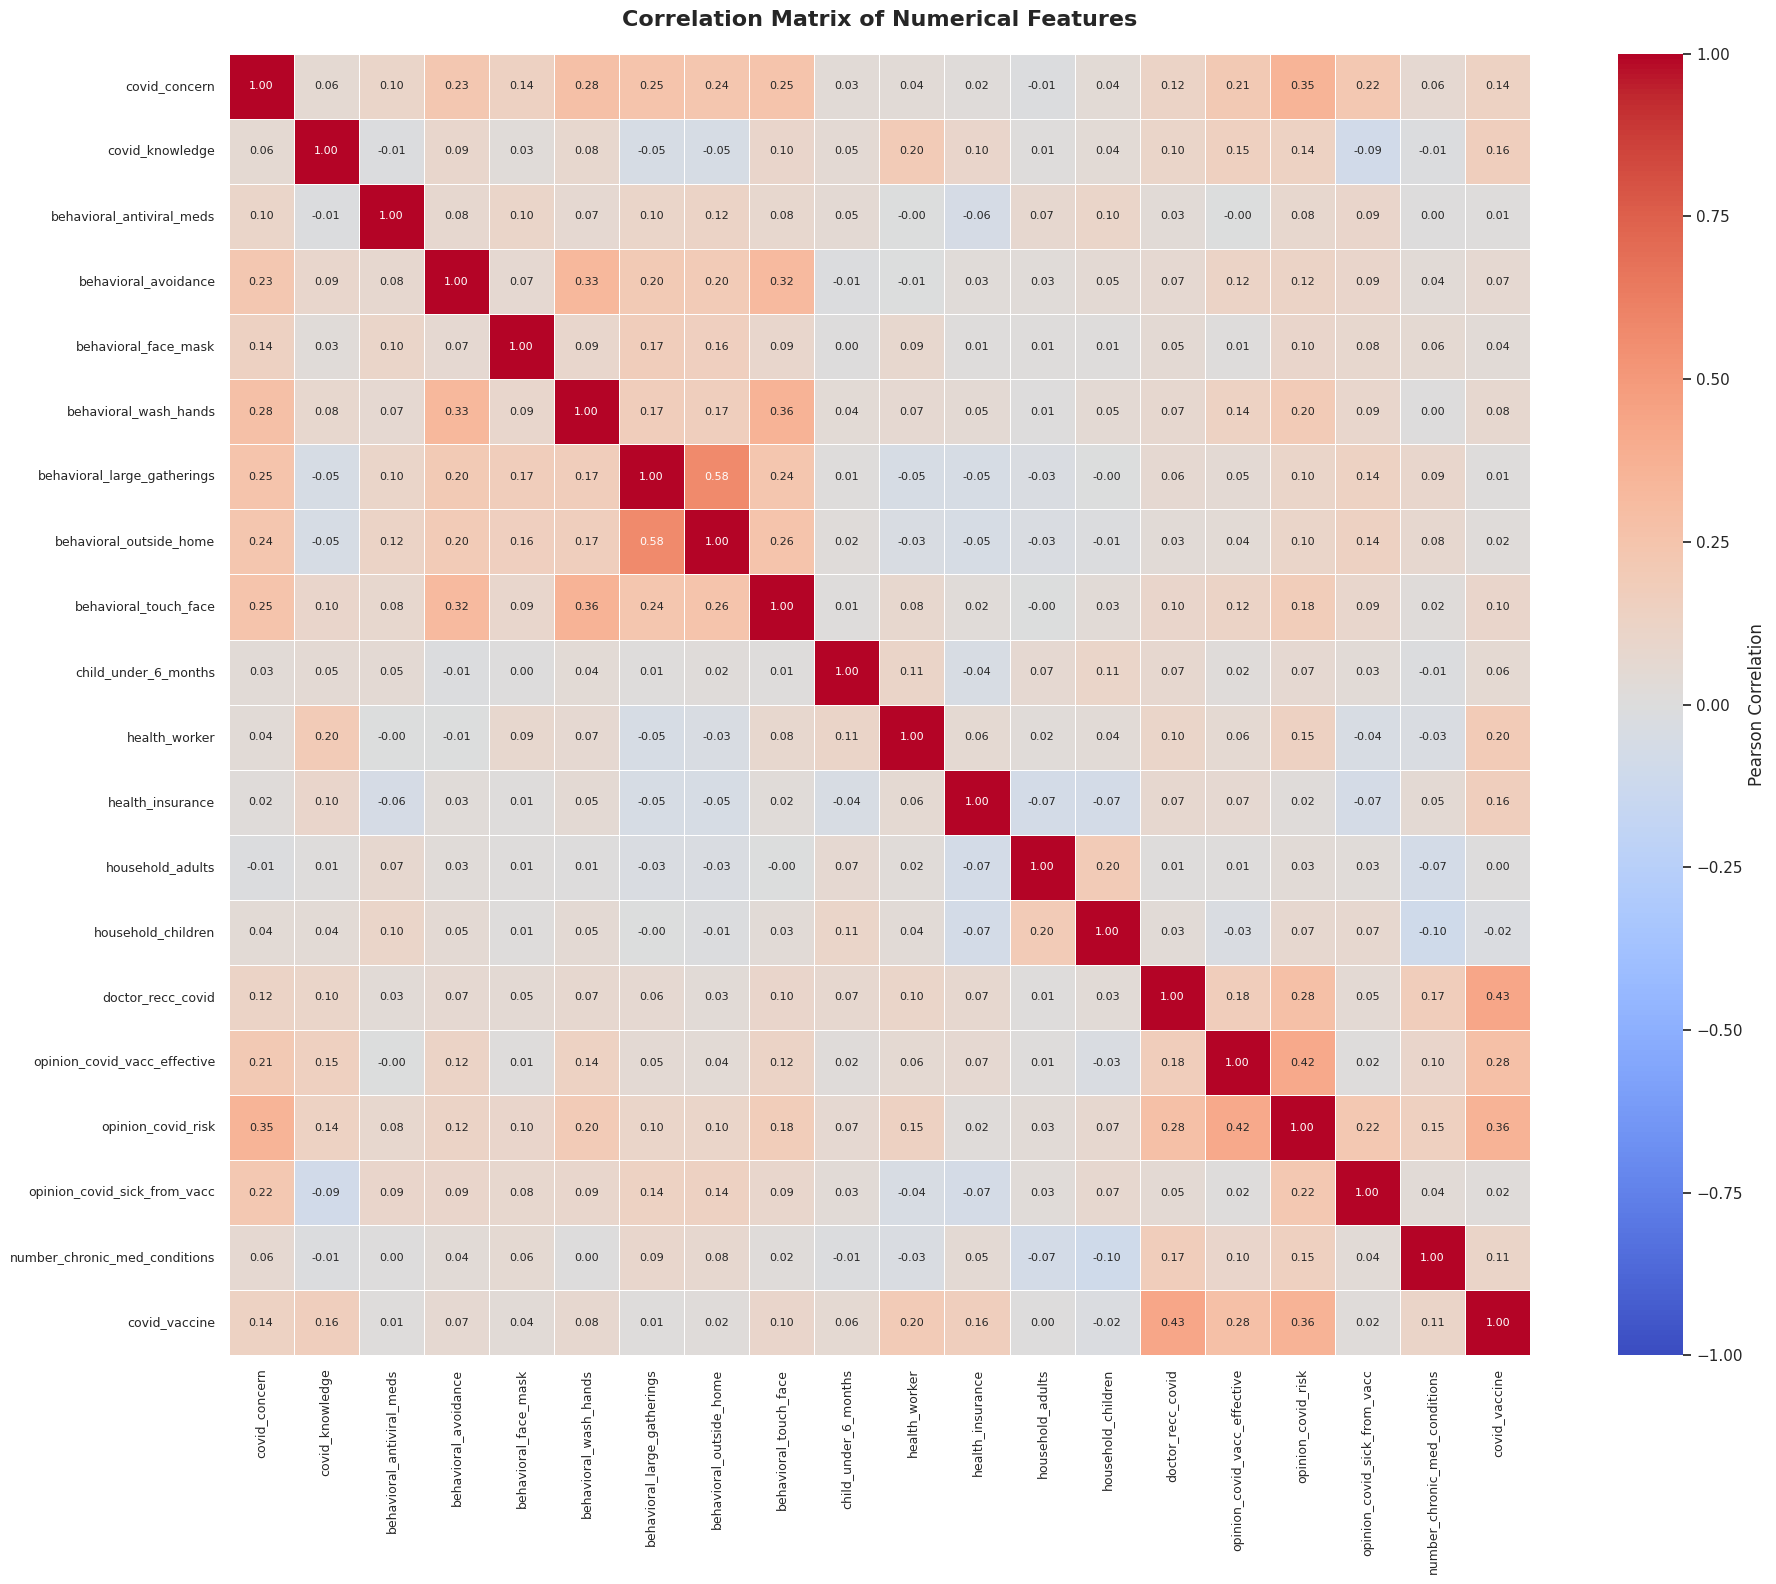

In [ ]:
# Select numerical features and exclude respondent ID
numeric_df = (
    train_df.drop(columns=["respondent_id"])
    .select_dtypes(include=np.number)
)

# Calculate Pearson correlation matrix
correlation_matrix = numeric_df.corr()

# Create correlation heatmap
plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    annot=True,             # Display correlation values
    fmt=".2f",              # Show two decimal places
    cmap="coolwarm",        # Colour scheme
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 8},
    square=True,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Matrix of Numerical Features",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


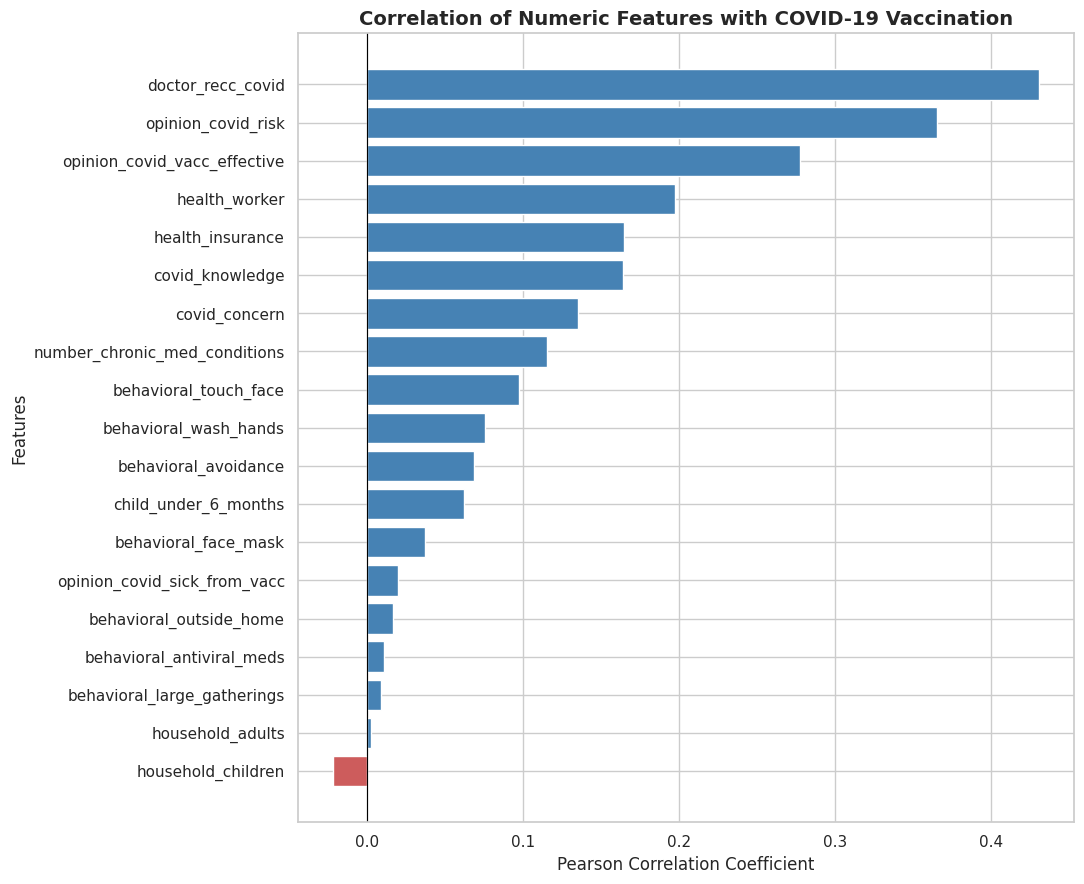

In [ ]:

# Correlations between numeric predictors and target
target_corr = (
    train_df
    .drop(columns=["respondent_id"])
    .select_dtypes(include=np.number)
    .corr()["covid_vaccine"]
    .drop("covid_vaccine")
    .sort_values()
)

# Create horizontal bar chart
plt.figure(figsize=(11, 9))

colors = [
    "steelblue" if value >= 0 else "indianred"
    for value in target_corr.values
]

plt.barh(
    target_corr.index,
    target_corr.values,
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title(
    "Correlation of Numeric Features with COVID-19 Vaccination",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


In [ ]:
#DATA PREPROCESSING
# Define target and identifier
TARGET = "covid_vaccine"
ID_COLUMN = "respondent_id"

# Separate predictors and target
X = train_df.drop(columns=[TARGET, ID_COLUMN])
y = train_df[TARGET]

# Prepare hidden test dataset
X_test = test_df.drop(columns=[ID_COLUMN])

# Verify column consistency
assert set(X.columns) == set(X_test.columns), \
    "Training and testing features do not match."

X_test = X_test[X.columns]

print("Training features:", X.shape)
print("Target:", y.shape)
print("Testing features:", X_test.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True).round(3))


Training features: (4756, 29)
Target: (4756,)
Testing features: (4749, 29)

Target distribution:
covid_vaccine
0    0.673
1    0.327
Name: proportion, dtype: float64


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", X_train.shape[0])
print("Validation observations:", X_val.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))


Training observations: 3804
Validation observations: 952

Training target distribution:
covid_vaccine
0    0.673239
1    0.326761
Name: proportion, dtype: float64

Validation target distribution:
covid_vaccine
0    0.673319
1    0.326681
Name: proportion, dtype: float64


In [ ]:

# Identify feature types
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nNumber of categorical features:",
      len(categorical_features))

print("Number of numerical features:",
      len(numerical_features))


Categorical features:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

Numerical features:
['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']

Number of categorical features: 10
Number of numerical features: 19


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


In [ ]:
#TRAIN BASELINE MODELS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.cluster import KMeans
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

# Store models and evaluation results
trained_models = {}
model_results = []

# Common evaluation function
def evaluate_model(name, model, X_val, y_val):

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    }

    model_results.append(metrics)
    trained_models[name] = model

    print(f"\n{name} — Classification Report")
    print(classification_report(
        y_val, y_pred, zero_division=0
    ))

    display(pd.DataFrame([metrics]).round(4))

print("Libraries and evaluation function ready.")


Libraries and evaluation function ready.


In [ ]:
#LOGISTIC REGRESSION
lr_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

evaluate_model(
    "Logistic Regression",
    lr_pipeline,
    X_val,
    y_val
)



Logistic Regression — Classification Report
              precision    recall  f1-score   support

           0       0.82      0.91      0.86       641
           1       0.75      0.58      0.65       311

    accuracy                           0.80       952
   macro avg       0.78      0.74      0.76       952
weighted avg       0.79      0.80      0.79       952



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7994,0.75,0.5788,0.6534,0.827


In [ ]:
#SUPPORT VECTOR MACHINE(SVM)
svm_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

svm_pipeline.fit(X_train, y_train)

evaluate_model(
    "SVM",
    svm_pipeline,
    X_val,
    y_val
)



SVM — Classification Report
              precision    recall  f1-score   support

           0       0.80      0.91      0.85       641
           1       0.73      0.53      0.61       311

    accuracy                           0.78       952
   macro avg       0.77      0.72      0.73       952
weighted avg       0.78      0.78      0.77       952



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVM,0.7826,0.7321,0.5273,0.6131,0.8148


In [ ]:
#RANDOM FOREST
rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

evaluate_model(
    "Random Forest",
    rf_pipeline,
    X_val,
    y_val
)



Random Forest — Classification Report
              precision    recall  f1-score   support

           0       0.79      0.91      0.85       641
           1       0.74      0.51      0.60       311

    accuracy                           0.78       952
   macro avg       0.77      0.71      0.73       952
weighted avg       0.78      0.78      0.77       952



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7815,0.7418,0.508,0.6031,0.8275


In [ ]:
#XG BOOST
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_train, y_train)

evaluate_model(
    "XGBoost",
    xgb_pipeline,
    X_val,
    y_val
)



XGBoost — Classification Report
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       641
           1       0.74      0.60      0.66       311

    accuracy                           0.80       952
   macro avg       0.78      0.75      0.76       952
weighted avg       0.79      0.80      0.79       952



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.7994,0.7381,0.5981,0.6607,0.8292


In [ ]:
#GRADIENT BOOSTING
gb_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_pipeline.fit(X_train, y_train)

evaluate_model(
    "Gradient Boosting",
    gb_pipeline,
    X_val,
    y_val
)



Gradient Boosting — Classification Report
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       641
           1       0.75      0.59      0.66       311

    accuracy                           0.80       952
   macro avg       0.78      0.74      0.76       952
weighted avg       0.79      0.80      0.79       952



,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.7994,0.7459,0.5852,0.6559,0.8334


In [ ]:
#K-MEANS CLUSTERING
from sklearn.metrics import adjusted_rand_score

# Fit preprocessing on training data only
kmeans_preprocessor = clone(preprocessor)

X_train_kmeans = kmeans_preprocessor.fit_transform(
    X_train
)

X_val_kmeans = kmeans_preprocessor.transform(
    X_val
)

# Train K-Means
kmeans = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)

train_clusters = kmeans.fit_predict(X_train_kmeans)
val_clusters = kmeans.predict(X_val_kmeans)

# Assign class labels using training data only
cluster_mapping = {}

for cluster in np.unique(train_clusters):

    labels = y_train.iloc[
        np.where(train_clusters == cluster)[0]
    ]

    cluster_mapping[cluster] = labels.mode().iloc[0]

kmeans_pred = np.array([
    cluster_mapping[c] for c in val_clusters
])

# Evaluation
kmeans_metrics = {
    "Model": "K-Means",
    "Accuracy": accuracy_score(y_val, kmeans_pred),
    "Precision": precision_score(
        y_val, kmeans_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, kmeans_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, kmeans_pred, zero_division=0
    ),
    "ROC-AUC": np.nan
}

model_results.append(kmeans_metrics)

print("K-Means — Classification Report")
print(classification_report(
    y_val, kmeans_pred, zero_division=0
))

print(
    "Adjusted Rand Index:",
    round(adjusted_rand_score(y_val, val_clusters), 4)
)

display(pd.DataFrame([kmeans_metrics]).round(4))


K-Means — Classification Report
              precision    recall  f1-score   support

           0       0.67      1.00      0.80       641
           1       0.00      0.00      0.00       311

    accuracy                           0.67       952
   macro avg       0.34      0.50      0.40       952
weighted avg       0.45      0.67      0.54       952

Adjusted Rand Index: 0.0275


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,K-Means,0.6733,0.0,0.0,0.0,NaN


In [ ]:
#MODEL COMPARISON AND VISUALISATION
results_df = pd.DataFrame(model_results)

# Rank supervised models by ROC-AUC
supervised_results = results_df[
    results_df["Model"] != "K-Means"
].copy()

supervised_results = supervised_results.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("SUPERVISED MODEL COMPARISON")
display(supervised_results.round(4))

print("\nK-MEANS EXPLORATORY RESULTS")
display(
    results_df[
        results_df["Model"] == "K-Means"
    ].round(4)
)


SUPERVISED MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.7994,0.7459,0.5852,0.6559,0.8334
1,XGBoost,0.7994,0.7381,0.5981,0.6607,0.8292
2,Random Forest,0.7815,0.7418,0.5080,0.6031,0.8275
3,Logistic Regression,0.7994,0.7500,0.5788,0.6534,0.8270
4,SVM,0.7826,0.7321,0.5273,0.6131,0.8148



K-MEANS EXPLORATORY RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
5,K-Means,0.6733,0.0,0.0,0.0,NaN


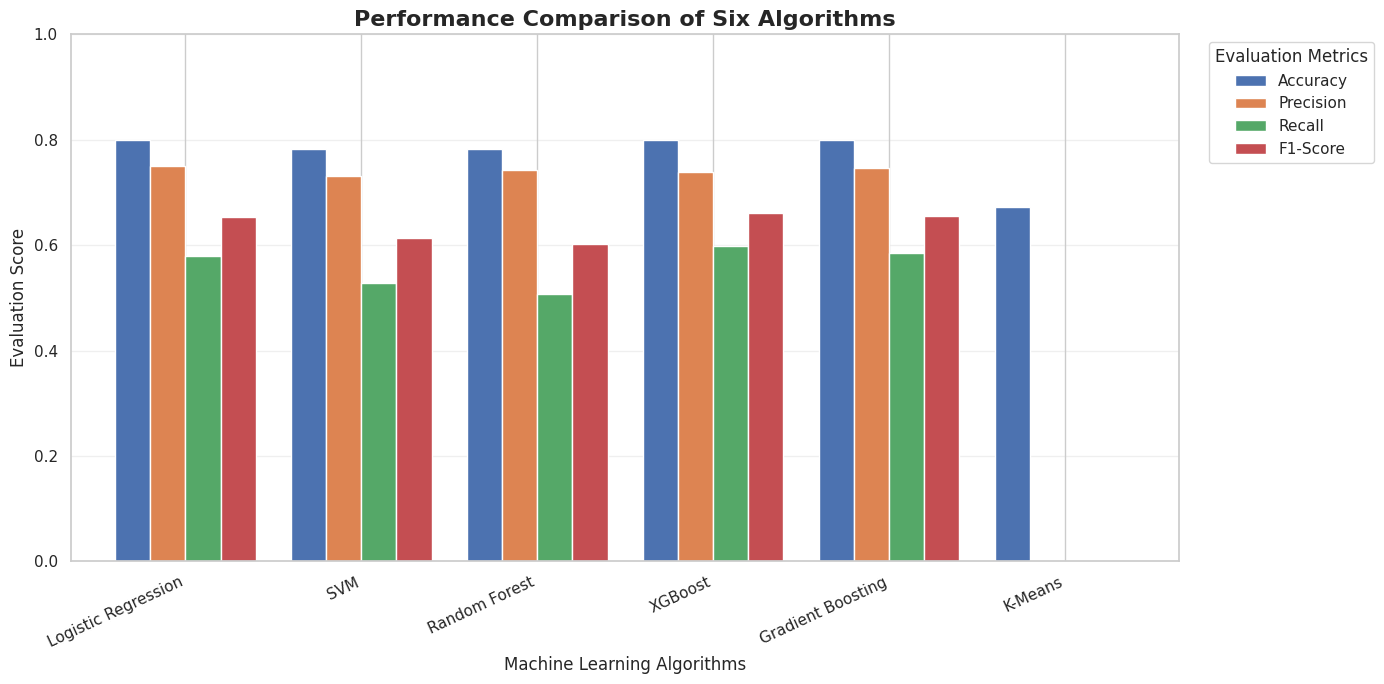

In [ ]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title(
    "Performance Comparison of Six Algorithms",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Evaluation Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Six_Models_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


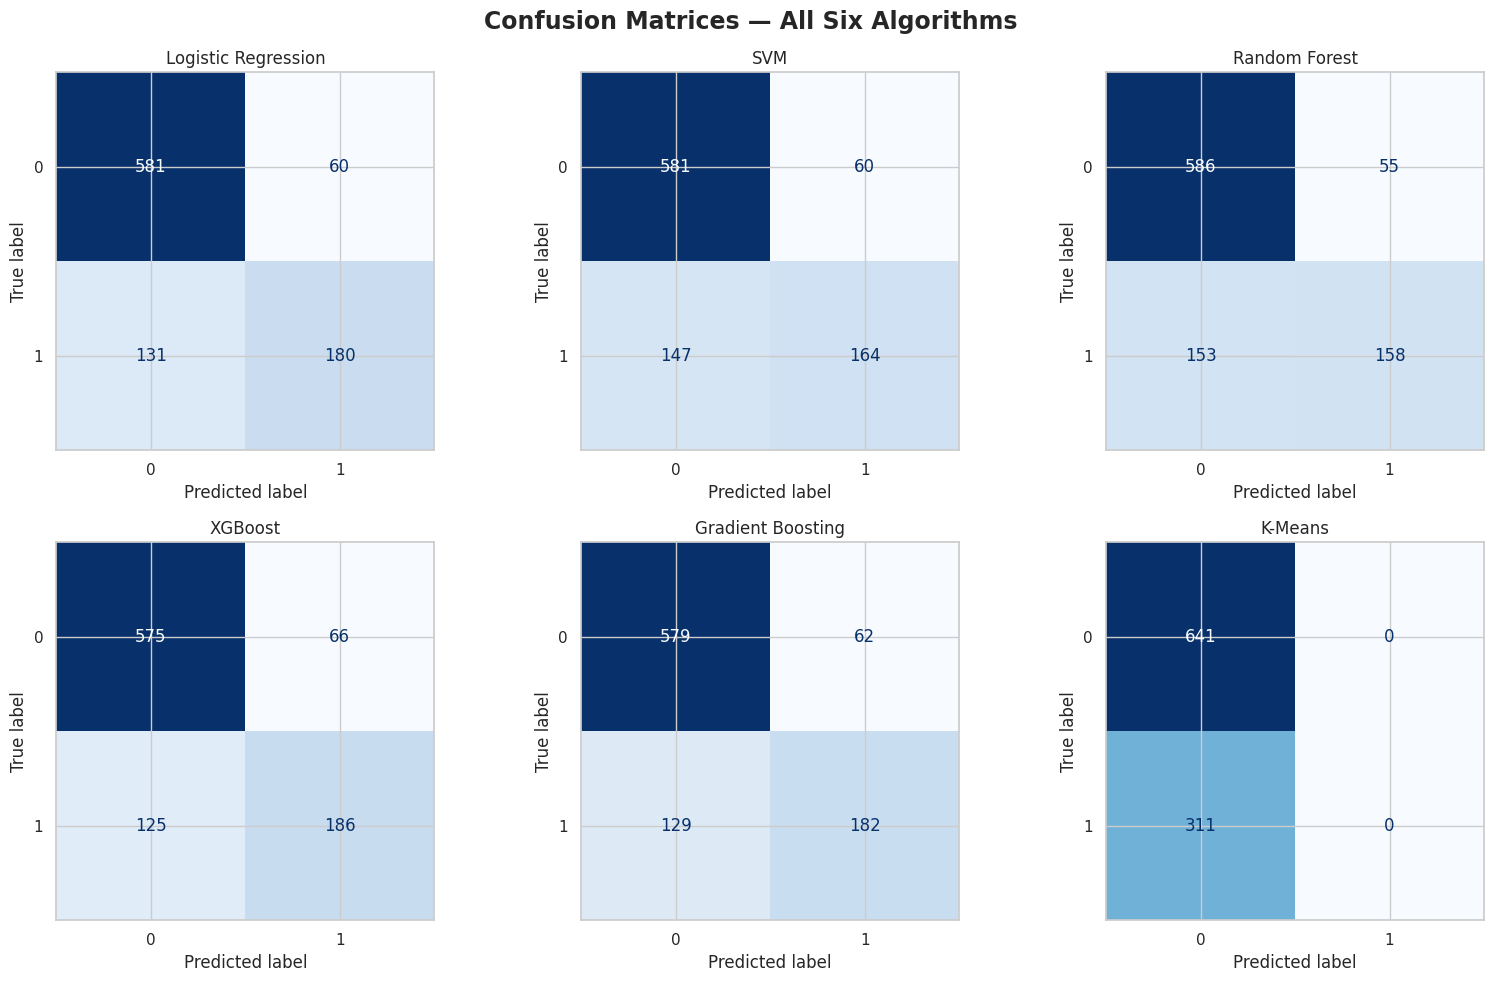

In [ ]:

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes = axes.flatten()

for i, (name, model) in enumerate(
    trained_models.items()
):

    predictions = model.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        ax=axes[i],
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    axes[i].set_title(name)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    kmeans_pred,
    ax=axes[5],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[5].set_title("K-Means")

plt.suptitle(
    "Confusion Matrices — All Six Algorithms",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Six_Models_Confusion_Matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


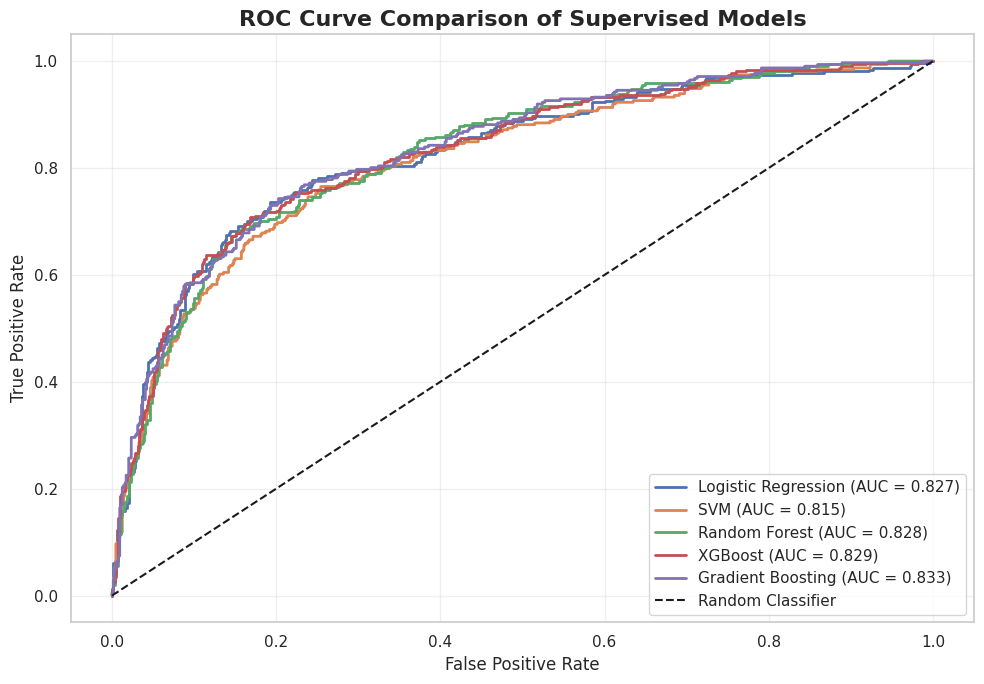

In [ ]:

plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.title(
    "ROC Curve Comparison of Supervised Models",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "ROC_Curve_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Rank supervised models only
ranked_models = supervised_results.sort_values(
    by=["ROC-AUC", "F1-Score"],
    ascending=False
).reset_index(drop=True)

best_model_name = ranked_models.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_auc = ranked_models.iloc[0]["ROC-AUC"]
best_accuracy = ranked_models.iloc[0]["Accuracy"]
best_precision = ranked_models.iloc[0]["Precision"]
best_recall = ranked_models.iloc[0]["Recall"]
best_f1 = ranked_models.iloc[0]["F1-Score"]


print("BEST SUPERVISED MODEL — VALIDATION ROC-AUC")


print(f"\nBest Model: {best_model_name}")
print(f"Accuracy : {best_accuracy:.4f}")
print(f"Precision: {best_precision:.4f}")
print(f"Recall   : {best_recall:.4f}")
print(f"F1-Score : {best_f1:.4f}")
print(f"ROC-AUC  : {best_auc:.4f}")

print("\nBEST MODEL BY EACH METRIC")

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]:
    top_row = supervised_results.loc[
        supervised_results[metric].idxmax()
    ]

    print(
        f"{metric:10s}: "
        f"{top_row['Model']} "
        f"({top_row[metric]:.4f})"
    )

print("\nFINAL SUPERVISED MODEL RANKING")
display(ranked_models.round(4))


BEST SUPERVISED MODEL — VALIDATION ROC-AUC

Best Model: Gradient Boosting
Accuracy : 0.7994
Precision: 0.7459
Recall   : 0.5852
F1-Score : 0.6559
ROC-AUC  : 0.8334

BEST MODEL BY EACH METRIC
Accuracy  : Gradient Boosting (0.7994)
Precision : Logistic Regression (0.7500)
Recall    : XGBoost (0.5981)
F1-Score  : XGBoost (0.6607)
ROC-AUC   : Gradient Boosting (0.8334)

FINAL SUPERVISED MODEL RANKING


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.7994,0.7459,0.5852,0.6559,0.8334
1,XGBoost,0.7994,0.7381,0.5981,0.6607,0.8292
2,Random Forest,0.7815,0.7418,0.5080,0.6031,0.8275
3,Logistic Regression,0.7994,0.7500,0.5788,0.6534,0.8270
4,SVM,0.7826,0.7321,0.5273,0.6131,0.8148


In [ ]:
#Stratified 5-Fold Cross-Validation
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

cv_results = []

for name, model in trained_models.items():

    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores[
            "test_Accuracy"
        ].mean(),
        "Mean Precision": scores[
            "test_Precision"
        ].mean(),
        "Mean Recall": scores[
            "test_Recall"
        ].mean(),
        "Mean F1": scores[
            "test_F1"
        ].mean(),
        "Mean ROC-AUC": scores[
            "test_ROC-AUC"
        ].mean(),
        "ROC-AUC Std": scores[
            "test_ROC-AUC"
        ].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("\n5-Fold Cross-Validation Results:")
display(cv_results_df.round(4))


Evaluating Logistic Regression...
Evaluating SVM...
Evaluating Random Forest...
Evaluating XGBoost...
Evaluating Gradient Boosting...

5-Fold Cross-Validation Results:


,Model,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,Mean ROC-AUC,ROC-AUC Std
0,XGBoost,0.7934,0.7280,0.5881,0.6501,0.8387,0.0163
1,Gradient Boosting,0.7973,0.7458,0.5777,0.6505,0.8377,0.0165
2,Random Forest,0.7894,0.7590,0.5213,0.6175,0.8295,0.0166
3,Logistic Regression,0.7955,0.7427,0.5736,0.6468,0.8276,0.0125
4,SVM,0.7931,0.7565,0.5423,0.6311,0.8209,0.0180


In [27]:
#HYPERPARAMETER TUNING

#Hyperparameter tuning for XGBoost
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from xgboost import XGBClassifier

tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

xgb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

xgb_param_grid = {
    "model__n_estimators": [100, 200, 300, 400],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(xgb_search.best_score_, 4))

best_xgb = xgb_search.best_estimator_


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best XGBoost Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 300, 'model__min_child_weight': 3, 'model__max_depth': 2, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}

Best CV ROC-AUC:
0.8382


In [28]:
#Hyperparameter tuning for Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

gb_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

gb_param_grid = {
    "model__n_estimators": [100, 150, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.8, 0.9, 1.0]
}

gb_search = RandomizedSearchCV(
    estimator=gb_tuning_pipeline,
    param_distributions=gb_param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

gb_search.fit(X_train, y_train)

print("Best Gradient Boosting Parameters:")
print(gb_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(gb_search.best_score_, 4))

best_gb = gb_search.best_estimator_


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Gradient Boosting Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_depth': 2, 'model__learning_rate': 0.1}

Best CV ROC-AUC:
0.8407


In [29]:
#COMPARING TUNED MODELS ON VALIDATION DATA
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

tuned_models = {
    "Tuned XGBoost": best_xgb,
    "Tuned Gradient Boosting": best_gb
}

tuned_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df = tuned_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

print("Tuned Model Validation Results:")
display(tuned_results_df.round(4))

print("\nBest Tuned Model by ROC-AUC:")
print(tuned_results_df.iloc[0]["Model"])


Tuned Model Validation Results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Tuned Gradient Boosting,0.8004,0.7354,0.6077,0.6655,0.8339
0,Tuned XGBoost,0.8015,0.7364,0.6109,0.6678,0.8339



Best Tuned Model by ROC-AUC:
Tuned Gradient Boosting


,Feature,Importance,Std
23,doctor_recc_covid,0.0916,0.0072
25,opinion_covid_risk,0.0568,0.0089
24,opinion_covid_vacc_effective,0.0268,0.0058
27,employment_sector,0.0120,0.0028
10,health_worker,0.0088,0.0028
12,age_group,0.0066,0.0034
13,education,0.0050,0.0027
14,race,0.0048,0.0012
6,behavioral_large_gatherings,0.0019,0.0017
15,sex,0.0011,0.0011


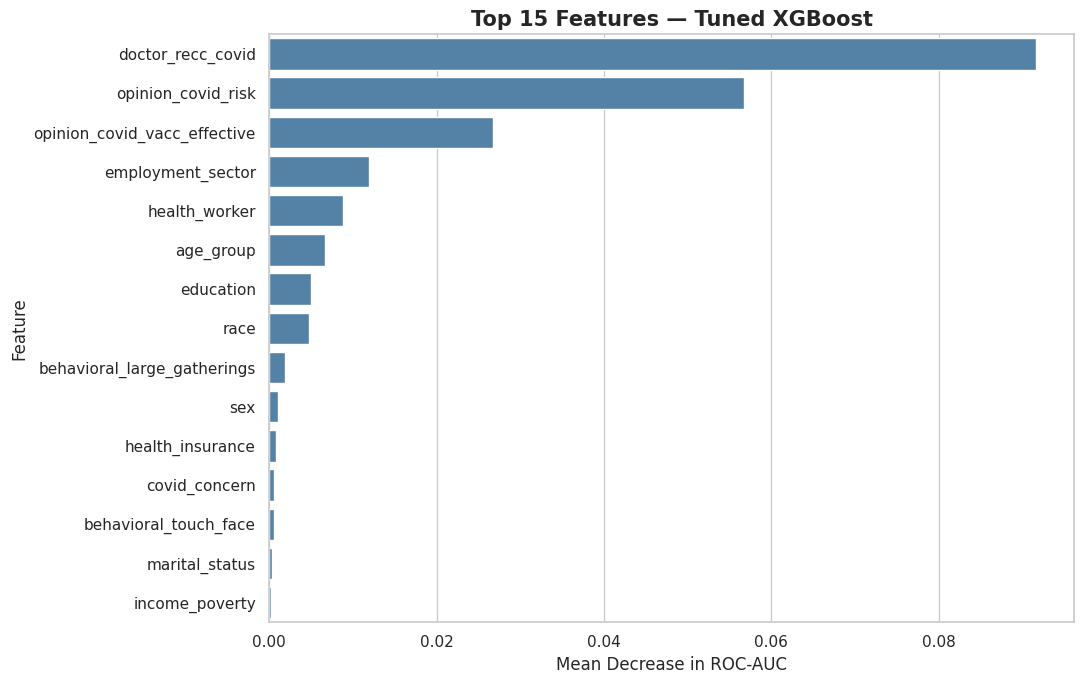

In [30]:
#FEATURE IMPORTANCE FOR TUNED XG BOOST
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

xgb_importance = permutation_importance(
    best_xgb,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

xgb_features = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": xgb_importance.importances_mean,
    "Std": xgb_importance.importances_std
})

xgb_features = xgb_features.sort_values(
    by="Importance",
    ascending=False
)

display(xgb_features.head(15).round(4))

plt.figure(figsize=(11, 7))

sns.barplot(
    data=xgb_features.head(15),
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Top 15 Features — Tuned XGBoost",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


,Feature,Importance,Std
23,doctor_recc_covid,0.0895,0.0070
25,opinion_covid_risk,0.0558,0.0089
24,opinion_covid_vacc_effective,0.0265,0.0050
27,employment_sector,0.0111,0.0031
10,health_worker,0.0081,0.0027
12,age_group,0.0070,0.0027
13,education,0.0036,0.0026
14,race,0.0023,0.0005
6,behavioral_large_gatherings,0.0010,0.0015
16,income_poverty,0.0010,0.0005


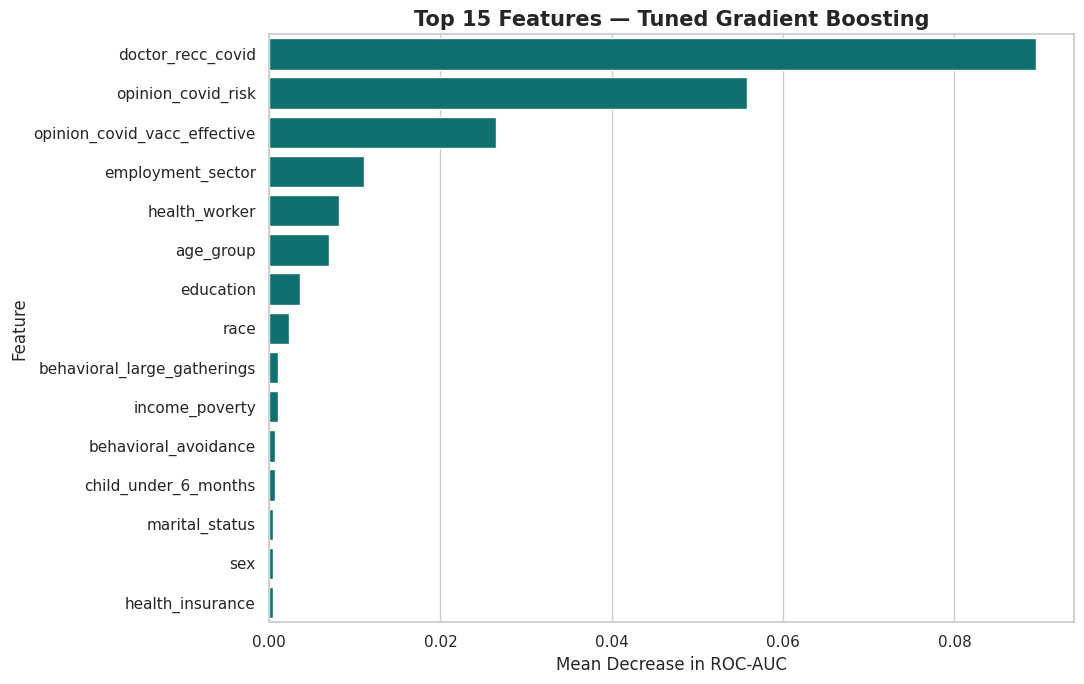

In [31]:
#FEATURE IMPORTANCE FOR GRADIENT BOOSTING
gb_importance = permutation_importance(
    best_gb,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

gb_features = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": gb_importance.importances_mean,
    "Std": gb_importance.importances_std
})

gb_features = gb_features.sort_values(
    by="Importance",
    ascending=False
)

display(gb_features.head(15).round(4))

plt.figure(figsize=(11, 7))

sns.barplot(
    data=gb_features.head(15),
    x="Importance",
    y="Feature",
    color="teal"
)

plt.title(
    "Top 15 Features — Tuned Gradient Boosting",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


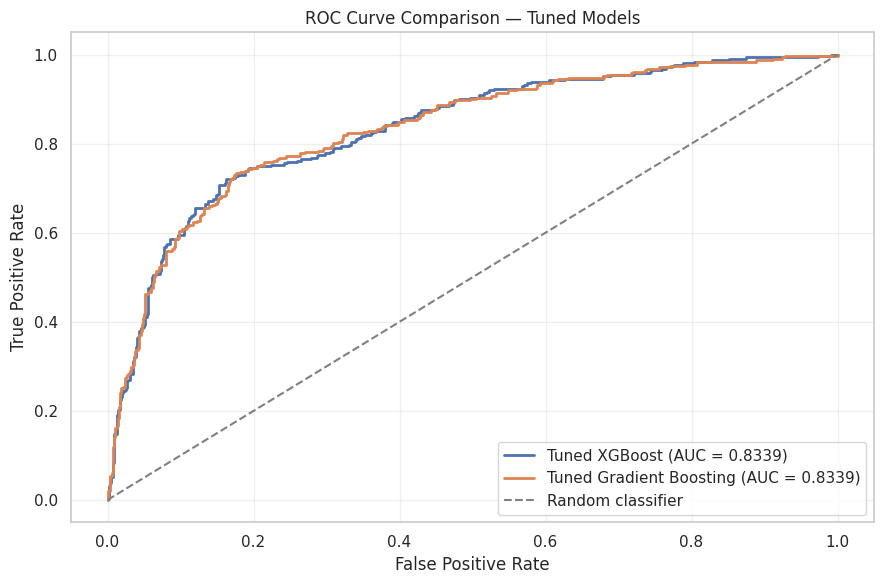

In [32]:
#ROC curve comparison
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

top_models = {
    "Tuned XGBoost": best_xgb,
    "Tuned Gradient Boosting": best_gb
}

plt.figure(figsize=(9, 6))

for name, model in top_models.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    fpr, tpr, _ = roc_curve(y_val, y_prob)
    auc = roc_auc_score(y_val, y_prob)

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — Tuned Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


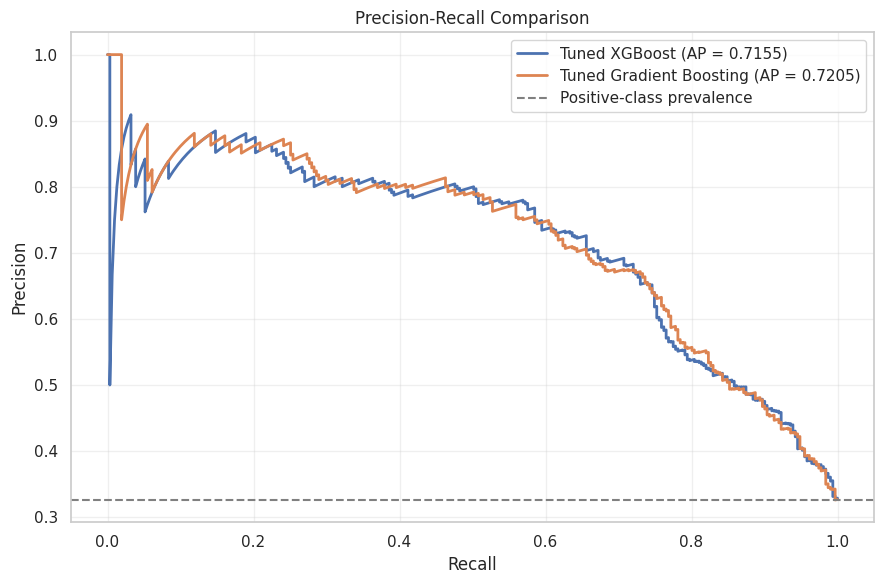

In [33]:
#Precision-recall curve comparison
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(9, 6))

for name, model in top_models.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_val, y_prob
    )

    ap = average_precision_score(y_val, y_prob)

    plt.plot(
        recall, precision,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    color="grey",
    label="Positive-class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


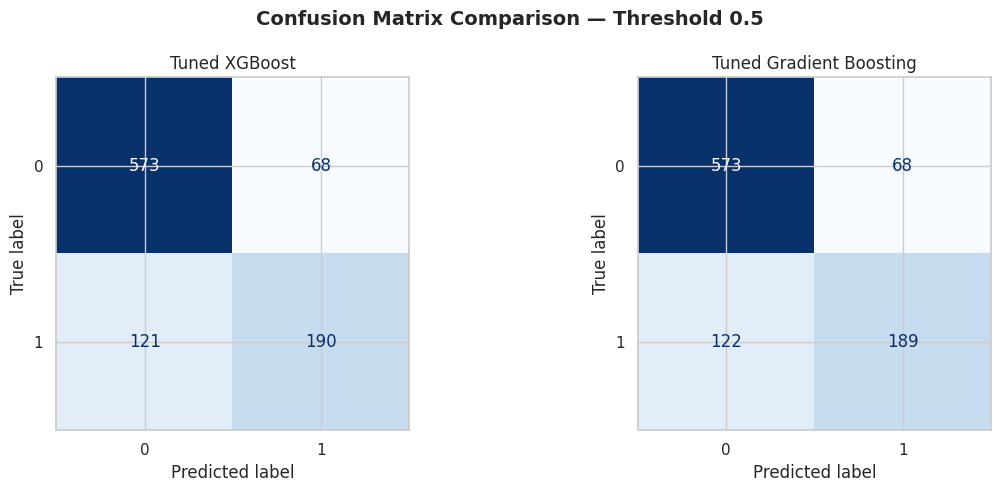

In [34]:
#Confusion matrix comparison
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(
    axes, top_models.items()
):

    y_pred = model.predict(X_val)

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        y_pred,
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

plt.suptitle(
    "Confusion Matrix Comparison — Threshold 0.5",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [35]:
#COST EFFECTIVE ANALYSIS
from sklearn.metrics import confusion_matrix
import pandas as pd

cost_models = {
    "Tuned XGBoost": best_xgb,
    "Tuned Gradient Boosting": best_gb
}

cost_results = []

for name, model in cost_models.items():

    y_pred = model.predict(X_val)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    cost_results.append({
        "Model": name,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

cost_df = pd.DataFrame(cost_results)

display(cost_df)


,Model,True Negatives,False Positives,False Negatives,True Positives
0,Tuned XGBoost,573,68,121,190
1,Tuned Gradient Boosting,573,68,122,189


,Model,Scenario,Total Cost,Cost per Respondent
0,Tuned XGBoost,Equal error costs,189000,198.529412
1,Tuned XGBoost,FN costs 2x FP,310000,325.630252
2,Tuned XGBoost,FN costs 5x FP,673000,706.932773
3,Tuned Gradient Boosting,Equal error costs,190000,199.579832
4,Tuned Gradient Boosting,FN costs 2x FP,312000,327.731092
5,Tuned Gradient Boosting,FN costs 5x FP,678000,712.184874


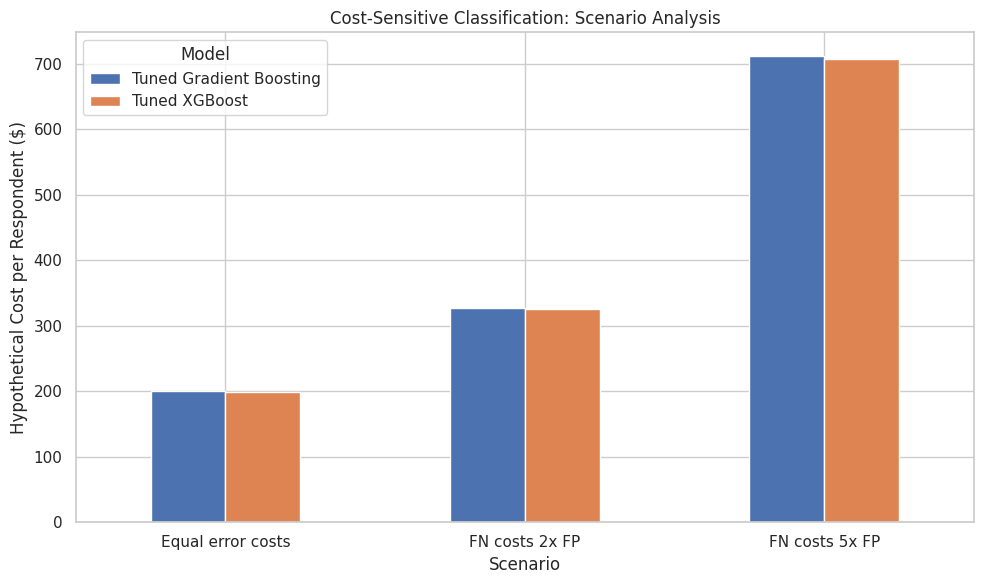

In [36]:
#Compare hypothetical misclassification costs
import pandas as pd
import matplotlib.pyplot as plt

# Illustrative error penalties, NOT hospitalisation costs
scenarios = {
    "Equal error costs": (1000, 1000),
    "FN costs 2x FP": (1000, 2000),
    "FN costs 5x FP": (1000, 5000)
}

scenario_results = []

for _, row in cost_df.iterrows():

    for scenario, (fp_cost, fn_cost) in scenarios.items():

        total_cost = (
            row["False Positives"] * fp_cost
            + row["False Negatives"] * fn_cost
        )

        scenario_results.append({
            "Model": row["Model"],
            "Scenario": scenario,
            "Total Cost": total_cost,
            "Cost per Respondent": total_cost / len(y_val)
        })

scenario_df = pd.DataFrame(scenario_results)

display(scenario_df)

pivot_cost = scenario_df.pivot(
    index="Scenario",
    columns="Model",
    values="Cost per Respondent"
)

ax = pivot_cost.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title(
    "Cost-Sensitive Classification: Scenario Analysis"
)
ax.set_ylabel("Hypothetical Cost per Respondent ($)")
ax.set_xlabel("Scenario")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Absolute Risk Reduction,Expected Hospital Cost Avoided,Vaccination Cost,Net Savings per Person
0,0.01,410.0,1500,-1090.0
1,0.02,820.0,1500,-680.0
2,0.03,1230.0,1500,-270.0
3,0.04,1640.0,1500,140.0
4,0.05,2050.0,1500,550.0
5,0.10,4100.0,1500,2600.0


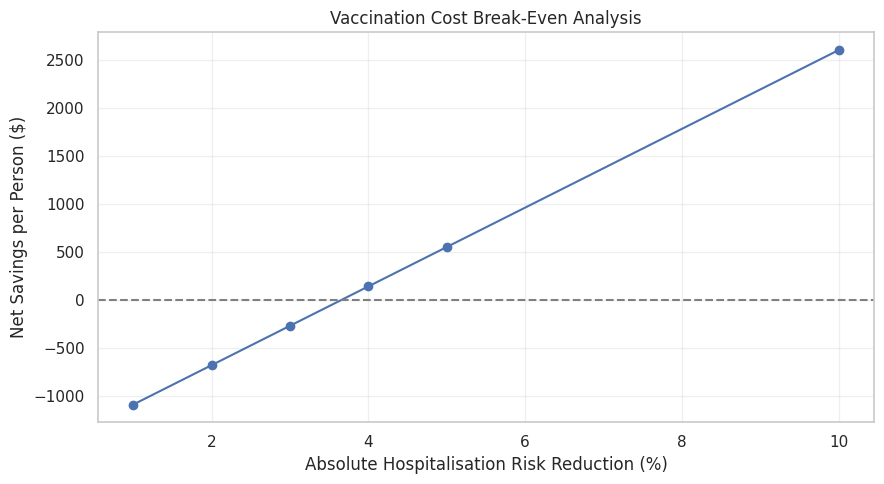

In [38]:
#Hospitalisation risk sensitivity analysis
import pandas as pd
import matplotlib.pyplot as plt

vaccination_cost = 1500
hospitalisation_cost = 41000

# Hypothetical absolute risk reductions
risk_reductions = [0.01, 0.02, 0.03, 0.04, 0.05, 0.10]

economic_results = []

for risk_reduction in risk_reductions:

    expected_savings = (
        risk_reduction * hospitalisation_cost
    )

    net_savings = expected_savings - vaccination_cost

    economic_results.append({
        "Absolute Risk Reduction": risk_reduction,
        "Expected Hospital Cost Avoided": expected_savings,
        "Vaccination Cost": vaccination_cost,
        "Net Savings per Person": net_savings
    })

economic_df = pd.DataFrame(economic_results)

display(economic_df.round(2))

plt.figure(figsize=(9, 5))

plt.plot(
    economic_df["Absolute Risk Reduction"] * 100,
    economic_df["Net Savings per Person"],
    marker="o"
)

plt.axhline(0, linestyle="--", color="grey")

plt.xlabel("Absolute Hospitalisation Risk Reduction (%)")
plt.ylabel("Net Savings per Person ($)")
plt.title("Vaccination Cost Break-Even Analysis")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [39]:
#RANKING SUPERVISED MODELS
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

final_models = {
    "Tuned XGBoost": best_xgb,
    "Tuned Gradient Boosting": best_gb,
    "Random Forest": trained_models["Random Forest"],
    "Logistic Regression": trained_models["Logistic Regression"],
    "SVM": trained_models["SVM"]
}

results = []

for name, model in final_models.items():
    y_pred = model.predict(X_val)
    y_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

final_results = (
    pd.DataFrame(results)
    .sort_values("ROC-AUC", ascending=False)
    .reset_index(drop=True)
)

final_results.insert(
    0, "Rank", range(1, len(final_results) + 1)
)

display(final_results.round(5))


,Rank,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,1,Tuned Gradient Boosting,0.80042,0.73541,0.60772,0.66549,0.83389
1,2,Tuned XGBoost,0.80147,0.73643,0.61093,0.66784,0.83388
2,3,Random Forest,0.78151,0.74178,0.50804,0.60305,0.82754
3,4,Logistic Regression,0.79937,0.75000,0.57878,0.65336,0.82703
4,5,SVM,0.78256,0.73214,0.52733,0.61308,0.81484


In [40]:
#COST SENSITIVE THRESHOLD ANALYSIS
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold, cross_val_predict
)
from sklearn.metrics import confusion_matrix

FP_COST = 1000
FN_COST = 2000

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

thresholds = np.arange(0.05, 0.951, 0.01)

optimisation_results = []
threshold_results = []

for name, model in final_models.items():

    # Out-of-fold probabilities on training data
    oof_prob = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Select threshold using training data only
    costs = []

    for threshold in thresholds:

        pred = (oof_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_train, pred, labels=[0, 1]
        ).ravel()

        total_cost = fp * FP_COST + fn * FN_COST
        costs.append(total_cost)

    best_index = int(np.argmin(costs))
    best_threshold = float(thresholds[best_index])

    # Evaluate selected threshold on validation data
    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= best_threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    validation_cost = fp * FP_COST + fn * FN_COST

    optimisation_results.append({
        "Model": name,
        "Optimal Threshold": best_threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Validation Cost": validation_cost,
        "Cost per Respondent": validation_cost / len(y_val)
    })

    threshold_results.append({
        "Model": name,
        "Threshold": best_threshold,
        "CV Training Cost": costs[best_index]
    })

cost_ranking = pd.DataFrame(
    optimisation_results
).sort_values(
    "Validation Cost",
    ascending=True
).reset_index(drop=True)

cost_ranking.insert(
    0, "Cost Rank", range(1, len(cost_ranking) + 1)
)

print("COST-SENSITIVE MODEL RANKING")
display(cost_ranking.round(4))


COST-SENSITIVE MODEL RANKING


,Cost Rank,Model,Optimal Threshold,False Positives,False Negatives,Validation Cost,Cost per Respondent
0,1,Tuned Gradient Boosting,0.33,127,79,285000,299.3697
1,2,Tuned XGBoost,0.33,133,78,289000,303.5714
2,3,Logistic Regression,0.30,158,69,296000,310.9244
3,4,Random Forest,0.35,135,88,311000,326.6807
4,5,SVM,0.27,145,89,323000,339.2857


In [41]:

import os
import zipfile
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone

# 1. Final model order

submission_models = [
    ("Tuned Gradient Boosting", best_gb, 0.33),
    ("Tuned XGBoost", best_xgb, 0.33),
    ("Logistic Regression",
     trained_models["Logistic Regression"], 0.30),
    ("Random Forest",
     trained_models["Random Forest"], 0.35),
    ("SVM",
     trained_models["SVM"], 0.27)
]

# 2. Validate input data

assert "respondent_id" in test_df.columns
assert "covid_vaccine" not in test_df.columns
assert test_df["respondent_id"].notna().all()
assert test_df["respondent_id"].is_unique

X_full = train_df.drop(
    columns=["respondent_id", "covid_vaccine"]
)

y_full = train_df["covid_vaccine"]

X_test_final = test_df.drop(
    columns=["respondent_id"]
)

assert set(X_full.columns) == set(X_test_final.columns)

X_test_final = X_test_final[X_full.columns]

assert len(X_test_final) == len(test_df)
assert set(y_full.dropna().unique()).issubset({0, 1})
assert y_full.notna().all()

# 3. Create output directories

output_dir = Path("/content/Dataset_C_Submissions")
prob_dir = output_dir / "probabilities"
binary_dir = output_dir / "binary_predictions"

prob_dir.mkdir(parents=True, exist_ok=True)
binary_dir.mkdir(parents=True, exist_ok=True)

manifest = []

# 4. Retrain each model on all labelled data

for rank, (name, model, threshold) in enumerate(
    submission_models, start=1
):

    print(f"Training {rank}/5: {name}")

    final_model = clone(model)
    final_model.fit(X_full, y_full)

    class_index = list(
        final_model.classes_
    ).index(1)

    probabilities = final_model.predict_proba(
        X_test_final
    )[:, class_index]

    binary_predictions = (
        probabilities >= threshold
    ).astype(int)

    # Probability submission
    probability_df = pd.DataFrame({
        "respondent_id": test_df["respondent_id"].to_numpy(),
        "covid_vaccine": probabilities
    })

    # Binary submission
    binary_df = pd.DataFrame({
        "respondent_id": test_df["respondent_id"].to_numpy(),
        "covid_vaccine": binary_predictions
    })

    # Validate outputs
    assert len(probability_df) == len(test_df)
    assert probability_df["respondent_id"].equals(
        test_df["respondent_id"].reset_index(drop=True)
    )
    assert np.isfinite(probabilities).all()
    assert np.all(
        (probabilities >= 0) & (probabilities <= 1)
    )
    assert set(np.unique(binary_predictions)).issubset(
        {0, 1}
    )

    prob_path = prob_dir / f"submission_{rank}.csv"
    binary_path = binary_dir / f"submission_{rank}.csv"

    probability_df.to_csv(prob_path, index=False)
    binary_df.to_csv(binary_path, index=False)

    manifest.append({
        "Rank": rank,
        "Model": name,
        "Threshold": threshold,
        "Rows": len(probability_df),
        "Mean Predicted Probability": probabilities.mean(),
        "Predicted Vaccination Rate": binary_predictions.mean()
    })

# 5. Save model manifest

manifest_df = pd.DataFrame(manifest)

manifest_df.to_csv(
    output_dir / "model_manifest.csv",
    index=False
)

print("\nFINAL SUBMISSION SUMMARY")
display(manifest_df.round(4))

# 6. Package both submission types

zip_path = Path("/content/Dataset_C_Submissions.zip")

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:

    for file in sorted(output_dir.rglob("*.csv")):
        archive.write(
            file,
            arcname=str(file.relative_to(output_dir))
        )

print("\nAll five models trained successfully.")
print("ZIP created:", zip_path)

# Download ZIP to your computer
from google.colab import files
files.download(str(zip_path))


Training 1/5: Tuned Gradient Boosting
Training 2/5: Tuned XGBoost
Training 3/5: Logistic Regression
Training 4/5: Random Forest
Training 5/5: SVM

FINAL SUBMISSION SUMMARY


,Rank,Model,Threshold,Rows,Mean Predicted Probability,Predicted Vaccination Rate
0,1,Tuned Gradient Boosting,0.33,4749,0.3356,0.3957
1,2,Tuned XGBoost,0.33,4749,0.3374,0.3961
2,3,Logistic Regression,0.30,4749,0.3371,0.4308
3,4,Random Forest,0.35,4749,0.3374,0.3900
4,5,SVM,0.27,4749,0.3347,0.3792



All five models trained successfully.
ZIP created: /content/Dataset_C_Submissions.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>